# Entregable 3

Incluye la fusión por concatenación de embeddings y transferencia de aprendizaje desde AstroM3-CLIP, con resultados comparativos frente a los modelos unimodales y la votación sobre sub50.

## 1. Preparación

In [1]:
!git clone https://github.com/David04Bucheli/proyecto-integrador.git
%cd proyecto-integrador

Cloning into 'proyecto-integrador'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 95 (delta 39), reused 44 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 947.52 KiB | 10.30 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/proyecto-integrador


In [2]:
import os, sys, json, time, platform
from pathlib import Path

REPO_URL = "https://github.com/David04Bucheli/proyecto-integrador.git"
if not os.path.isdir("src"):
    if os.path.isdir("../src"):
        os.chdir("..")
    elif REPO_URL:
        os.system(f"git clone {REPO_URL} repo_clone")
        os.chdir("repo_clone")
    else:
        raise RuntimeError("No encuentro la carpeta src/. Ejecuta desde la raíz del repo")
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: /content/proyecto-integrador


In [3]:
%pip install -q -r requirements.txt

In [4]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src import config, datasets, models, engine, embeddings, runs, fusion, reporting, concat, transfer, compare, leakage

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = torch.cuda.get_device_name(0) if DEVICE == "cuda" else None
print("Dispositivo:", DEVICE, "|", GPU)
print("torch", torch.__version__, "| python", platform.python_version())

SUBSET = config.SUBSET_FORMAL
OUT = Path("outputs_e3")
for d in ("checkpoints", "predictions", "figures", "embeddings"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

E2_CHECKPOINTS = Path("outputs_e2/checkpoints")
RUN_AUDIT = True
RUN_CHANNEL_ABLATION = True

Dispositivo: cuda | NVIDIA L4
torch 2.14.1+cu130 | python 3.13.16


In [5]:
ds = datasets.load_subset(SUBSET)
print(ds)
label_names = ds["train"].features["label"].names
print("Clases del dataset:", label_names)
assert list(label_names) == config.CLASS_NAMES, "El orden de las clases no coincide con config.CLASS_NAMES"

README.md:   0%|          | 0.00/23.5k [00:00<?, ?B/s]

sub50_42/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  230MB            

sub50_42/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sub50_42/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 29.5MB            

sub50_42/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

sub50_42/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 30.4MB            

sub50_42/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8526 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1071 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1111 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 8526
    })
    validation: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 1071
    })
    test: Dataset({
        features: ['photometry', 'spectra', 'metadata', 'label'],
        num_rows: 1111
    })
})
Clases del dataset: ['DSCT', 'EA', 'EB', 'EW', 'HADS', 'M', 'ROT', 'RRAB', 'RRC', 'SR']


### Protocolo

- **Auditoría:** huellas de metadatos, fotometría (canales 0–2) y espectro (canales 0–1); solo cuentan las que superan el control positivo. Si una huella válida encuentra objetos de validación o prueba en full/train, la transferencia no se ejecuta.
- **Unimodales:** mismos modelos y protocolo del Entregable 2 (Adam, lr 1e-3, batch 32, 20 épocas, semilla 42, modelo de la última época). Si están los checkpoints del Entregable 2 en `outputs_e2/checkpoints` se cargan; si no, se reentrenan.
- **Ablación de canales:** la misma GRU entrenada solo con los canales 0–2 de la fotometría.
- **Concatenación:** embeddings de 64 valores de cada modalidad → vector de 192 (fotometría | espectros | metadatos), estandarizado con la media y la desviación de train. Encima, un MLP. Capa oculta (0 = lineal, 128, 256), dropout (0.1, 0.3) y weight decay (0, 1e-4) se eligen con el macro-F1 de validación. Parada temprana con validación (paciencia 10, máximo 100 épocas).
- **Transferencia:** pesos de `AstroMLCore/AstroM3-CLIP` (preentrenado con la semilla 42, la misma partición) y código oficial de AstroM3 fijado al commit `7f296c2`.
    - *Congelado:* los pesos preentrenados no cambian. Se extraen sus embeddings (3 × 512) y encima se entrena la misma cabeza MLP con la misma búsqueda que la concatenación.
    - *Ajuste fino:* se actualizan todos los pesos, con fusión por promedio y una capa lineal nueva de 10 clases. Hiperparámetros publicados por los autores para sub50 con preentrenamiento (`configs/config-all-sub50-clip.yaml`). Se guarda el estado con mejor macro-F1 en validación.
    - La fotometría entra con 200 pasos: recorte aleatorio en train y central en validación y prueba, igual que el código oficial.
- **Prueba:** todas las elecciones se hacen con validación; la partición de prueba solo se muestra en la sección 7. Las diferencias entre estrategias se acompañan con un bootstrap pareado (2000 remuestreos).
- Una sola corrida (semilla 42).

## 2. Auditoría de integridad

AstroM3-CLIP se preentrenó con full/train. Antes de usarlo se busca si algún objeto de validación o prueba de sub50 está en full/train.

La huella de metadatos del Entregable 1 no sirve entre configuraciones: `preprocess.py` de AstroM3Dataset estandariza los metadatos con la media y la desviación del train de cada configuración, así que el mismo objeto tiene valores distintos en full y en sub50. En cambio, los canales 0–2 de la fotometría (tiempo, flujo y error) y los canales 0–1 del espectro (flujo y error) se normalizan por objeto y no dependen de la configuración.

Se prueban las tres huellas con varias precisiones. El control positivo decide cuál es válida: como sub50 sale de las particiones de full, una huella válida debe encontrar en full/train casi todos los objetos de sub50/train. Solo las huellas válidas cuentan para la decisión.

In [6]:
AUDIT, VERDICT, AUDIT_OK = None, None, None
if RUN_AUDIT:
    full = datasets.load_subset(config.SUBSET_FULL)
    AUDIT = leakage.audit_table(full["train"], {"train": ds["train"], "validation": ds["validation"], "test": ds["test"]})
    del full
    display(AUDIT)
    VERDICT = leakage.decide(AUDIT)
    AUDIT_OK = VERDICT["ok"]
    print(VERDICT["message"])
    print("Huellas válidas:", VERDICT["valid"])

full_42/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  232MB            

full_42/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

full_42/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  229MB            

full_42/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

full_42/validation-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 58.7MB            

full_42/validation-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

... (3 outputs left out)

Generating validation split:   0%|          | 0/2152 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2225 [00:00<?, ? examples/s]

filas referencia  huellas únicas referencia  \
huella     decimales                                                
metadatos  3                     17063                      17063   
           4                     17063                      17063   
           6                     17063                      17063   
fotometria 3                     17063                      17063   
           4                     17063                      17063   
           6                     17063                      17063   
espectros  3                     17063                      17063   
           4                     17063                      17063   
           6                     17063                      17063   

                      únicas train  coincidencias train  únicas validation  \
huella     decimales                                                         
metadatos  3                  8526                    0               1071   
           4                  8526                    0               1071   
           6                  8526                    0               1071   
fotometria 3                  8526                 8526               1071   
           4                  8526                 8526               1071   
           6                  8526                 8526               1071   
espectros  3                  8526                 8526               1071   
           4                  8526                 8526               1071   
           6                  8526                 8526               1071   

                      coincidencias validation  únicas test  \
huella     decimales                                          
metadatos  3                                 0         1111   
           4                                 0         1111   
           6                                 0         1111   
fotometria 3                                 0         1111   
           4                                 0         1111   
           6                                 0         1111   
espectros  3                                 0         1111   
           4                                 0         1111   
           6                                 0         1111   

                      coincidencias test  control positivo (recuperación)  \
huella     decimales                                                        
metadatos  3                           0                              0.0   
           4                           0                              0.0   
           6                           0                              0.0   
fotometria 3                           0                              1.0   
           4                           0                              1.0   
           6                           0                              1.0   
espectros  3                           0                              1.0   
           4                           0                              1.0   
           6                           0                              1.0   

                      huella válida  
huella     decimales                 
metadatos  3                  False  
           4                  False  
           6                  False  
fotometria 3                   True  
           4                   True  
           6                   True  
espectros  3                   True  
           4                   True  
           6                   True

Las huellas válidas no encuentran objetos de validación ni de prueba en el preentrenamiento.
Huellas válidas: ['fotometria@3', 'fotometria@4', 'fotometria@6', 'espectros@3', 'espectros@4', 'espectros@6']


## 3. Modelos unimodales

In [7]:
NAMES = ["fotometria", "espectros", "metadatos"]
FWD = {"fotometria": engine.forward_fn_photometry,
       "espectros": engine.forward_fn_spectra,
       "metadatos": engine.forward_fn_metadata}

def build(name):
    torch.manual_seed(config.SEED)
    if name == "fotometria":
        enc = models.PhotometryGRUEncoder(input_dim=len(ds["train"][0]["photometry"][0]))
    elif name == "espectros":
        enc = models.SpectraCNNEncoder(in_channels=len(ds["train"][0]["spectra"]))
    else:
        enc = models.MetadataMLPEncoder(input_dim=len(ds["train"][0]["metadata"]))
    return models.UnimodalClassifier(enc)

train_loader = datasets.make_dataloader(ds["train"], shuffle=True)
loaders = {s: datasets.make_dataloader(ds[s], shuffle=False) for s in ("train", "validation", "test")}
MODELS, COST = {}, {}
for name in NAMES:
    model = build(name)
    ckpt = E2_CHECKPOINTS / f"{name}_{SUBSET}.pt"
    if ckpt.exists():
        info = runs.load_checkpoint_into(model, ckpt, which="last", device=DEVICE)
        origin = "checkpoint E2"
    else:
        print(f"\n===== {name} (reentrenando) =====")
        fr = runs.fit_with_checkpoints(model, train_loader, loaders["validation"], FWD[name],
                                       device=DEVICE, class_names=config.CLASS_NAMES)
        ckpt = OUT / "checkpoints" / f"{name}_{SUBSET}.pt"
        runs.save_checkpoint(ckpt, fr, extra={"seed": config.SEED, "subset": SUBSET})
        info = runs.load_checkpoint_into(model, ckpt, which="last", device=DEVICE)
        origin = "reentrenado E3"
    MODELS[name] = model
    COST[name] = {"origen": origin, "parametros_entrenables": info["n_parameters"],
                  "segundos_entrenamiento": round(info["train_seconds"], 1)}
display(pd.DataFrame(COST).T)


===== fotometria (reentrenando) =====
[01/20] train_loss=0.9299 train_acc=0.666 | val_loss=0.6202 val_acc=0.776 val_macroF1=0.787
[02/20] train_loss=0.5417 train_acc=0.797 | val_loss=0.5771 val_acc=0.780 val_macroF1=0.795
[03/20] train_loss=0.4953 train_acc=0.804 | val_loss=0.4613 val_acc=0.821 val_macroF1=0.821
[04/20] train_loss=0.4459 train_acc=0.825 | val_loss=0.4494 val_acc=0.811 val_macroF1=0.814
[05/20] train_loss=0.4133 train_acc=0.844 | val_loss=0.3948 val_acc=0.849 val_macroF1=0.860
[06/20] train_loss=0.3781 train_acc=0.857 | val_loss=0.3542 val_acc=0.865 val_macroF1=0.871
[07/20] train_loss=0.3532 train_acc=0.865 | val_loss=0.3881 val_acc=0.852 val_macroF1=0.867
[08/20] train_loss=0.3448 train_acc=0.870 | val_loss=0.3538 val_acc=0.866 val_macroF1=0.872
[09/20] train_loss=0.3249 train_acc=0.878 | val_loss=0.4088 val_acc=0.844 val_macroF1=0.843
[10/20] train_loss=0.3221 train_acc=0.877 | val_loss=0.3397 val_acc=0.873 val_macroF1=0.871
[11/20] train_loss=0.3137 train_acc=0.883

,origen,parametros_entrenables,segundos_entrenamiento
fotometria,reentrenado E3,19338,446.4
espectros,reentrenado E3,28618,344.9
metadatos,reentrenado E3,11338,336.5


In [8]:
PRED = {"validation": {}, "test": {}}
for split in PRED:
    for n in NAMES:
        PRED[split][n] = runs.predict_proba(MODELS[n], loaders[split], DEVICE, FWD[n])
        runs.save_predictions(OUT / "predictions" / f"{n}_{SUBSET}_{split}.npz", PRED[split][n])
    fusion.check_alignment([PRED[split][n]["y_true"] for n in NAMES])
Y = {s: PRED[s]["fotometria"]["y_true"] for s in PRED}
display(pd.DataFrame({n: {"exactitud (validation)": float((PRED["validation"][n]["y_pred"] == Y["validation"]).mean()),
                          "macro-F1 (validation)": compare.macro_f1(Y["validation"], PRED["validation"][n]["y_pred"])}
                      for n in NAMES}).T.round(4))

,exactitud (validation),macro-F1 (validation)
fotometria,0.8945,0.9118
espectros,0.6359,0.5140
metadatos,0.8133,0.7994


### 3b. Ablación de canales de la fotometría

Los canales 3–8 de la fotometría son constantes dentro de cada curva: son descriptores del objeto que AstroM3 movió de los metadatos a la fotometría (amplitud, periodo, estadístico de Lafler-Kinman, variabilidad pico a pico, log MAD y extensión temporal). Para separar lo que aporta la curva de lo que aportan esos descriptores, se entrena la misma GRU, con el mismo protocolo, solo con los canales 0–2.

In [9]:
CORE_CHANNELS = 3

def forward_core(model, batch):
    logits, _ = model(batch["photometry"][..., :CORE_CHANNELS], batch["photometry_lengths"])
    return logits, batch["label"]

PRED_CORE = None
if RUN_CHANNEL_ABLATION:
    torch.manual_seed(config.SEED)
    gru_core = models.UnimodalClassifier(models.PhotometryGRUEncoder(input_dim=CORE_CHANNELS))
    FR_CORE = runs.fit_with_checkpoints(gru_core, train_loader, loaders["validation"], forward_core,
                                        device=DEVICE, class_names=config.CLASS_NAMES)
    runs.save_checkpoint(OUT / "checkpoints" / f"fotometria_canales012_{SUBSET}.pt", FR_CORE,
                         extra={"seed": config.SEED, "subset": SUBSET, "channels": [0, 1, 2]})
    PRED_CORE = {s: runs.predict_proba(gru_core, loaders[s], DEVICE, forward_core) for s in ("validation", "test")}
    print("macro-F1 de validación | 9 canales:", round(compare.macro_f1(Y["validation"], PRED["validation"]["fotometria"]["y_pred"]), 4),
          "| canales 0-2:", round(compare.macro_f1(Y["validation"], PRED_CORE["validation"]["y_pred"]), 4))

[01/20] train_loss=1.6861 train_acc=0.370 | val_loss=1.4189 val_acc=0.498 val_macroF1=0.393
[02/20] train_loss=1.2638 train_acc=0.531 | val_loss=1.2900 val_acc=0.506 val_macroF1=0.399
[03/20] train_loss=1.0825 train_acc=0.608 | val_loss=1.0846 val_acc=0.610 val_macroF1=0.498
[04/20] train_loss=0.9735 train_acc=0.645 | val_loss=1.2842 val_acc=0.567 val_macroF1=0.485
[05/20] train_loss=0.8999 train_acc=0.668 | val_loss=0.9312 val_acc=0.655 val_macroF1=0.540
[06/20] train_loss=0.8289 train_acc=0.697 | val_loss=0.9109 val_acc=0.679 val_macroF1=0.603
[07/20] train_loss=0.8059 train_acc=0.706 | val_loss=0.8865 val_acc=0.674 val_macroF1=0.569
[08/20] train_loss=0.7729 train_acc=0.718 | val_loss=0.8564 val_acc=0.693 val_macroF1=0.610
[09/20] train_loss=0.7454 train_acc=0.726 | val_loss=0.8115 val_acc=0.705 val_macroF1=0.599
[10/20] train_loss=0.7306 train_acc=0.731 | val_loss=0.7871 val_acc=0.723 val_macroF1=0.624
[11/20] train_loss=0.7055 train_acc=0.741 | val_loss=0.7932 val_acc=0.712 val_ma

## 4. Votación (referencia del Entregable 2)

In [10]:
PRIORITY = fusion.rank_by_validation({n: compare.macro_f1(Y["validation"], PRED["validation"][n]["y_pred"]) for n in NAMES})

def vote(split, rule):
    return fusion.hard_vote({n: PRED[split][n]["y_pred"] for n in NAMES}, tie_break=rule, priority=PRIORITY,
                            probs={n: PRED[split][n]["probs"] for n in NAMES})["y_pred"]

VAL_RULE = {r: compare.macro_f1(Y["validation"], vote("validation", r)) for r in fusion.TIE_BREAKS}
CHOSEN_RULE = max(VAL_RULE, key=VAL_RULE.get)
VOTE = {s: vote(s, CHOSEN_RULE) for s in Y}
SOFT = {s: fusion.soft_vote({n: PRED[s][n]["probs"] for n in NAMES}) for s in Y}
print("Macro-F1 de validación por regla:", {k: round(v, 4) for k, v in VAL_RULE.items()}, "| elegida:", CHOSEN_RULE)

Macro-F1 de validación por regla: {'priority': 0.9007, 'confidence': 0.8989, 'error': 0.867} | elegida: priority


## 5. Fusión por concatenación de embeddings

Los embeddings de entrenamiento salen de codificadores entrenados con esos mismos objetos, así que son más limpios que los de validación y prueba. Por eso la cabeza se elige y se detiene con validación.

In [11]:
EMB = {}
for s in ("train", "validation", "test"):
    parts = {n: embeddings.extract_embeddings(MODELS[n], loaders[s], DEVICE, FWD[n]) for n in NAMES}
    fusion.check_alignment([parts[n]["labels"] for n in NAMES])
    EMB[s] = embeddings.concatenate_modalities(parts["fotometria"]["embeddings"], parts["espectros"]["embeddings"],
                                               parts["metadatos"]["embeddings"], parts["fotometria"]["labels"])
    embeddings.save_embeddings(str(OUT / "embeddings" / f"fused_{SUBSET}_{s}.npz"), EMB[s]["embeddings"], EMB[s]["labels"])
for s in ("validation", "test"):
    assert np.array_equal(EMB[s]["labels"], Y[s])

Guardado: outputs_e3/embeddings/fused_sub50_train.npz  (embeddings: (8526, 192), labels: (8526,))
Guardado: outputs_e3/embeddings/fused_sub50_validation.npz  (embeddings: (1071, 192), labels: (1071,))
Guardado: outputs_e3/embeddings/fused_sub50_test.npz  (embeddings: (1111, 192), labels: (1111,))


{'hidden_dim': 0, 'dropout': 0.1, 'weight_decay': 0.0, 'val_macro_f1': 0.9465809699563297, 'best_epoch': 28, 'n_parameters': 1930, 'seconds': 5.2}
{'hidden_dim': 0, 'dropout': 0.1, 'weight_decay': 0.0001, 'val_macro_f1': 0.9465809699563297, 'best_epoch': 28, 'n_parameters': 1930, 'seconds': 5.3}
{'hidden_dim': 0, 'dropout': 0.3, 'weight_decay': 0.0, 'val_macro_f1': 0.9495955326423076, 'best_epoch': 28, 'n_parameters': 1930, 'seconds': 5.3}
{'hidden_dim': 0, 'dropout': 0.3, 'weight_decay': 0.0001, 'val_macro_f1': 0.9427851824334363, 'best_epoch': 13, 'n_parameters': 1930, 'seconds': 3.2}
{'hidden_dim': 128, 'dropout': 0.1, 'weight_decay': 0.0, 'val_macro_f1': 0.952361724995218, 'best_epoch': 8, 'n_parameters': 25994, 'seconds': 3.2}
{'hidden_dim': 128, 'dropout': 0.1, 'weight_decay': 0.0001, 'val_macro_f1': 0.9523232110893003, 'best_epoch': 8, 'n_parameters': 25994, 'seconds': 3.3}
{'hidden_dim': 128, 'dropout': 0.3, 'weight_decay': 0.0, 'val_macro_f1': 0.9507990283415315, 'best_epoch':

,hidden_dim,dropout,weight_decay,val_macro_f1,best_epoch,n_parameters,seconds
4,128,0.1,0.0000,0.9524,8,25994,3.2
5,128,0.1,0.0001,0.9523,8,25994,3.3
7,128,0.3,0.0001,0.9518,16,25994,4.7
6,128,0.3,0.0000,0.9508,13,25994,4.1
2,0,0.3,0.0000,0.9496,28,1930,5.3
10,256,0.3,0.0000,0.9485,2,51978,2.1
11,256,0.3,0.0001,0.9478,2,51978,2.2
9,256,0.1,0.0001,0.9475,2,51978,2.2
8,256,0.1,0.0000,0.9475,2,51978,2.2
0,0,0.1,0.0000,0.9466,28,1930,5.2


Configuración elegida: {'hidden_dim': 128, 'dropout': 0.1, 'weight_decay': 0.0, 'lr': 0.001, 'batch_size': 64, 'max_epochs': 100, 'patience': 10} | mejor época: 8 | parámetros: 25994


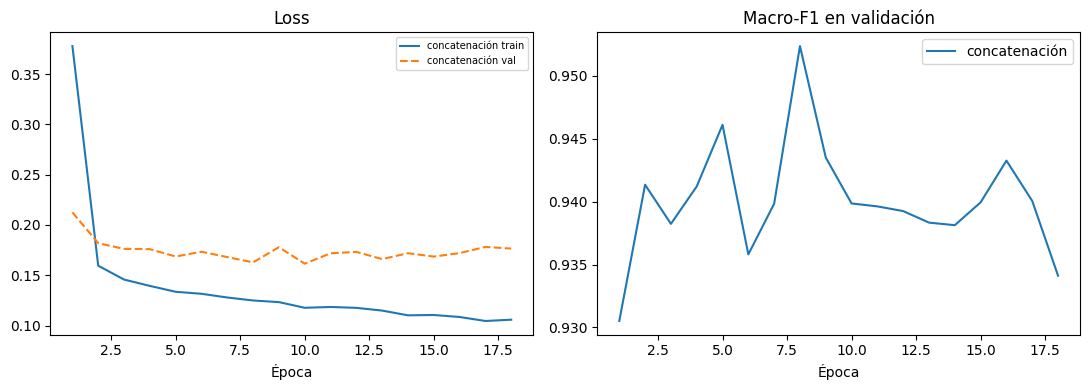

In [12]:
GS_CONCAT = concat.grid_search(EMB["train"]["embeddings"], EMB["train"]["labels"],
                               EMB["validation"]["embeddings"], EMB["validation"]["labels"], device=DEVICE)
CONCAT = GS_CONCAT["best"]
display(pd.DataFrame(GS_CONCAT["table"]).sort_values("val_macro_f1", ascending=False).round(4))
print("Configuración elegida:", CONCAT["params"], "| mejor época:", CONCAT["best_epoch"],
      "| parámetros:", CONCAT["n_parameters"])
concat.save_head(OUT / "checkpoints" / f"concat_{SUBSET}.pt", CONCAT, extra={"seed": config.SEED, "subset": SUBSET})
PRED_CONCAT = {s: concat.predict_proba_head(CONCAT, EMB[s]["embeddings"], EMB[s]["labels"], DEVICE) for s in Y}
reporting.plot_history({"concatenación": CONCAT["history"]}, path=OUT / "figures" / "curvas_concatenacion.png")
plt.show()

In [13]:
COMBOS = [("fotometria",), ("fotometria", "metadatos"), ("fotometria", "espectros"),
          ("espectros", "metadatos"), tuple(NAMES)]
best_hp = {k: CONCAT["params"][k] for k in ("hidden_dim", "dropout", "weight_decay")}
ABLATION = {}
for combo in COMBOS:
    X = {s: concat.take_modalities(EMB[s]["embeddings"], combo, config.EMBEDDING_DIM) for s in EMB}
    fit = concat.train_head(X["train"], EMB["train"]["labels"], X["validation"], EMB["validation"]["labels"],
                            device=DEVICE, **best_hp)
    ABLATION[" + ".join(combo)] = {"macro-F1 (validation)": compare.macro_f1(
        Y["validation"], concat.predict_proba_head(fit, X["validation"], device=DEVICE)["y_pred"]),
        "mejor época": fit["best_epoch"]}
ABLATION = pd.DataFrame(ABLATION).T.round(4)
display(ABLATION)

,macro-F1 (validation),mejor época
fotometria,0.9186,13.0
fotometria + metadatos,0.9437,5.0
fotometria + espectros,0.9412,3.0
espectros + metadatos,0.8578,21.0
fotometria + espectros + metadatos,0.9524,8.0


## 6. Transferencia desde AstroM3-CLIP

Se descarga el código oficial de AstroM3 (fijado a un commit) y los pesos desde Hugging Face. La celda se detiene si la auditoría encontró coincidencias.

In [14]:
assert AUDIT_OK is not False, "La auditoría encontró coincidencias: no se usa AstroM3-CLIP"
if AUDIT_OK is None:
    print("Aviso: la auditoría no se ejecutó en esta sesión")
ROOT = transfer.fetch_astrom3_code()
CACHE = {s: transfer.CachedSplit(ds[s]) for s in ("train", "validation", "test")}
print({s: len(v) for s, v in CACHE.items()})

{'train': 8526, 'validation': 1071, 'test': 1111}


### 6a. Modelo preentrenado congelado

In [15]:
clip_enc, clip_info = transfer.load_clip_encoder(config.CLIP_MODEL_NAME, ROOT)
print("Tensores cargados:", clip_info["n_tensors"], "| faltantes:", clip_info["missing"], "| sobrantes:", clip_info["unexpected"])
print("Parámetros del modelo preentrenado:", f"{sum(p.numel() for p in clip_enc.parameters()):,}")

t0 = time.time()
CLIP_EMB = {}
for s in CACHE:
    e = transfer.extract_clip_embeddings(clip_enc, transfer.make_clip_loader(CACHE[s], train=False, batch_size=256), DEVICE)
    assert np.array_equal(e["labels"], EMB[s]["labels"])
    CLIP_EMB[s] = {"embeddings": np.concatenate([e[n] for n in NAMES], axis=1), "labels": e["labels"]}
    np.savez(OUT / "embeddings" / f"clip_{SUBSET}_{s}.npz", **CLIP_EMB[s])
CLIP_EXTRACT_SECONDS = time.time() - t0
print("Embeddings AstroM3-CLIP:", CLIP_EMB["train"]["embeddings"].shape, f"| extracción: {CLIP_EXTRACT_SECONDS:.0f} s")
del clip_enc
if DEVICE == "cuda":
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 66.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Tensores cargados: 153 | faltantes: [] | sobrantes: []
Parámetros del modelo preentrenado: 15,869,827
Embeddings AstroM3-CLIP: (8526, 1536) | extracción: 4 s


In [16]:
GS_FROZEN = concat.grid_search(CLIP_EMB["train"]["embeddings"], CLIP_EMB["train"]["labels"],
                               CLIP_EMB["validation"]["embeddings"], CLIP_EMB["validation"]["labels"], device=DEVICE)
FROZEN = GS_FROZEN["best"]
display(pd.DataFrame(GS_FROZEN["table"]).sort_values("val_macro_f1", ascending=False).round(4))
print("Configuración elegida:", FROZEN["params"], "| mejor época:", FROZEN["best_epoch"],
      "| parámetros:", FROZEN["n_parameters"])
concat.save_head(OUT / "checkpoints" / f"astrom3_congelado_{SUBSET}.pt", FROZEN, extra={"seed": config.SEED, "subset": SUBSET})
PRED_FROZEN = {s: concat.predict_proba_head(FROZEN, CLIP_EMB[s]["embeddings"], CLIP_EMB[s]["labels"], DEVICE) for s in Y}

{'hidden_dim': 0, 'dropout': 0.1, 'weight_decay': 0.0, 'val_macro_f1': 0.9338860082824336, 'best_epoch': 6, 'n_parameters': 15370, 'seconds': 2.2}
{'hidden_dim': 0, 'dropout': 0.1, 'weight_decay': 0.0001, 'val_macro_f1': 0.9338860082824336, 'best_epoch': 6, 'n_parameters': 15370, 'seconds': 2.3}
{'hidden_dim': 0, 'dropout': 0.3, 'weight_decay': 0.0, 'val_macro_f1': 0.9348444425393655, 'best_epoch': 2, 'n_parameters': 15370, 'seconds': 1.7}
{'hidden_dim': 0, 'dropout': 0.3, 'weight_decay': 0.0001, 'val_macro_f1': 0.9348444425393655, 'best_epoch': 2, 'n_parameters': 15370, 'seconds': 1.8}
{'hidden_dim': 128, 'dropout': 0.1, 'weight_decay': 0.0, 'val_macro_f1': 0.9357693099404998, 'best_epoch': 2, 'n_parameters': 198026, 'seconds': 2.2}
{'hidden_dim': 128, 'dropout': 0.1, 'weight_decay': 0.0001, 'val_macro_f1': 0.9345116784680935, 'best_epoch': 6, 'n_parameters': 198026, 'seconds': 3.0}
{'hidden_dim': 128, 'dropout': 0.3, 'weight_decay': 0.0, 'val_macro_f1': 0.9359155200295961, 'best_epoc

,hidden_dim,dropout,weight_decay,val_macro_f1,best_epoch,n_parameters,seconds
10,256,0.3,0.0000,0.9395,2,396042,2.3
11,256,0.3,0.0001,0.9371,2,396042,2.4
7,128,0.3,0.0001,0.9361,2,198026,2.3
6,128,0.3,0.0000,0.9359,2,198026,2.2
8,256,0.1,0.0000,0.9358,2,396042,2.3
4,128,0.1,0.0000,0.9358,2,198026,2.2
2,0,0.3,0.0000,0.9348,2,15370,1.7
3,0,0.3,0.0001,0.9348,2,15370,1.8
9,256,0.1,0.0001,0.9347,10,396042,3.9
5,128,0.1,0.0001,0.9345,6,198026,3.0


Configuración elegida: {'hidden_dim': 256, 'dropout': 0.3, 'weight_decay': 0.0, 'lr': 0.001, 'batch_size': 64, 'max_epochs': 100, 'patience': 10} | mejor época: 2 | parámetros: 396042


### 6b. Ajuste fino de todo el modelo

Capas nuevas: ['fc.weight', 'fc.bias']
Hiperparámetros: {'fusion': 'avg', 'p_dropout': 0.08116365514804472, 's_dropout': 0.03454530839892027, 'm_dropout': 0.2721805507275124, 'lr': 0.0038789663081484622, 'beta1': 0.8628516428717157, 'beta2': 0.999, 'weight_decay': 8.297980301069488e-05, 'epochs': 50, 'batch_size': 512, 'warmup_epochs': 10, 'scheduler_factor': 0.2571022327438819, 'scheduler_patience': 3, 'early_stopping_patience': 6}
[01/50] lr=3.88e-08 train_loss=2.2986 train_acc=0.151 | val_loss=2.2987 val_acc=0.142 val_macroF1=0.114
[02/50] lr=3.88e-04 train_loss=2.1136 train_acc=0.654 | val_loss=1.9401 val_acc=0.780 val_macroF1=0.540
[03/50] lr=7.76e-04 train_loss=1.7660 train_acc=0.805 | val_loss=1.6035 val_acc=0.835 val_macroF1=0.724
[04/50] lr=1.16e-03 train_loss=1.4218 train_acc=0.857 | val_loss=1.2496 val_acc=0.888 val_macroF1=0.865
[05/50] lr=1.55e-03 train_loss=1.0747 train_acc=0.892 | val_loss=0.9204 val_acc=0.910 val_macroF1=0.908
[06/50] lr=1.94e-03 train_loss=0.7963 train

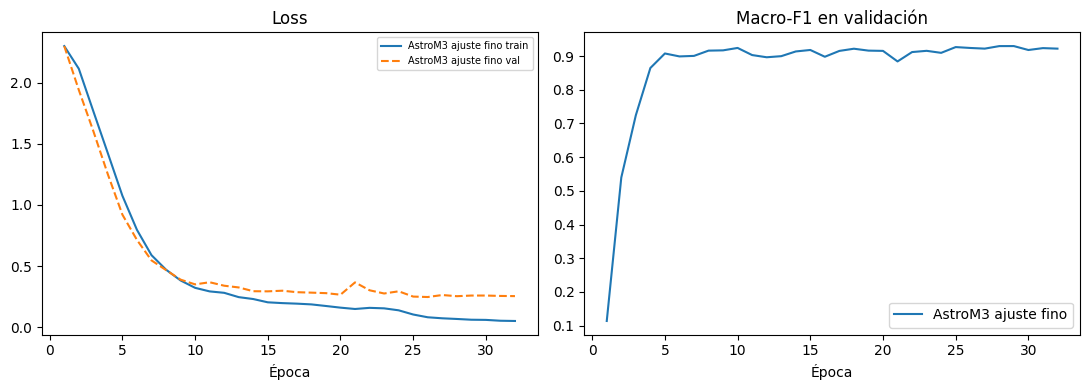

In [17]:
torch.manual_seed(config.SEED)
HP = dict(transfer.FINETUNE_HP)
ft_model, ft_info = transfer.build_finetune_model(config.CLIP_MODEL_NAME, ROOT, hp=HP)
print("Capas nuevas:", ft_info["new_layers"])
print("Hiperparámetros:", HP)
ft_train_loader = transfer.make_clip_loader(CACHE["train"], train=True, batch_size=HP["batch_size"])
CLIP_LOADERS = {s: transfer.make_clip_loader(CACHE[s], train=False, batch_size=256) for s in ("validation", "test")}
FT = transfer.finetune(ft_model, ft_train_loader, CLIP_LOADERS["validation"], DEVICE, hp=HP, class_names=config.CLASS_NAMES)
runs.save_checkpoint(OUT / "checkpoints" / f"astrom3_ajuste_fino_{SUBSET}.pt", FT,
                     extra={"seed": config.SEED, "subset": SUBSET, "hp": HP, "astrom3_commit": transfer.ASTROM3_COMMIT})
print(f"Mejor época (macro-F1 de validación): {FT['best_epoch']} de {FT['stopped_epoch']} | {FT['train_seconds']:.0f} s | {FT['n_parameters']:,} parámetros entrenables")
reporting.plot_history({"AstroM3 ajuste fino": FT["history"]}, path=OUT / "figures" / "curvas_astrom3_ajuste_fino.png")
plt.show()

In [18]:
PRED_FT = {s: runs.predict_proba(ft_model, CLIP_LOADERS[s], DEVICE, transfer.forward_fn_clip) for s in Y}
for s in Y:
    assert np.array_equal(PRED_FT[s]["y_true"], Y[s])
    runs.save_predictions(OUT / "predictions" / f"astrom3_ajuste_fino_{SUBSET}_{s}.npz", PRED_FT[s])

## 7. Comparación de estrategias

,exactitud (validation),macro-F1 (validation),exactitud (test),macro-F1 (test),parametros_entrenables,segundos_entrenamiento
GRU (fotometría),0.8945,0.9118,0.8911,0.9077,19338.0,446.4
CNN 1D (espectros),0.6359,0.5140,0.6436,0.5134,28618.0,344.9
MLP (metadatos),0.8133,0.7994,0.8128,0.7891,11338.0,336.5
Votación 2 de 3 (priority),0.8898,0.9007,0.8803,0.8844,0.0,0.0
"GRU (fotometría, canales 0-2)",0.7535,0.6622,0.7777,0.6910,18186.0,447.9
Voto suave (referencia),0.9104,0.9195,0.9091,0.9135,0.0,0.0
Concatenación + MLP,0.9440,0.9524,0.9325,0.9379,25994.0,3.2
AstroM3-CLIP congelado + MLP,0.9328,0.9395,0.9181,0.9264,396042.0,6.2
AstroM3-CLIP ajuste fino,0.9225,0.9291,0.9244,0.9280,15874957.0,250.4


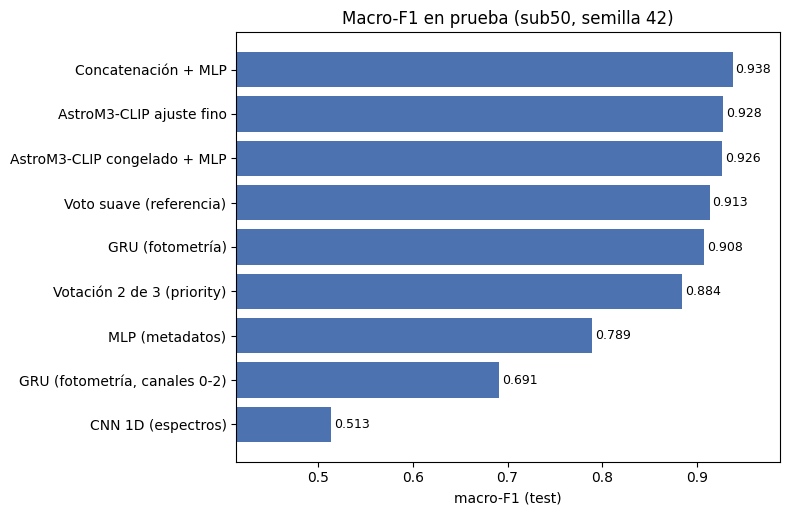

In [19]:
def entry(preds, params, seconds):
    return {**{s: {"y_true": Y[s], "y_pred": preds[s]} for s in Y},
            "parametros_entrenables": int(params), "segundos_entrenamiento": round(float(seconds), 1)}

LABELS = {"fotometria": "GRU (fotometría)", "espectros": "CNN 1D (espectros)", "metadatos": "MLP (metadatos)"}
ENTRIES = {LABELS[n]: entry({s: PRED[s][n]["y_pred"] for s in Y}, COST[n]["parametros_entrenables"],
                            COST[n]["segundos_entrenamiento"]) for n in NAMES}
ENTRIES[f"Votación 2 de 3 ({CHOSEN_RULE})"] = entry(VOTE, 0, 0)
if PRED_CORE is not None:
    ENTRIES["GRU (fotometría, canales 0-2)"] = entry({s: PRED_CORE[s]["y_pred"] for s in Y}, FR_CORE["n_parameters"],
                                                     FR_CORE["train_seconds"])
ENTRIES["Voto suave (referencia)"] = entry(SOFT, 0, 0)
ENTRIES["Concatenación + MLP"] = entry({s: PRED_CONCAT[s]["y_pred"] for s in Y}, CONCAT["n_parameters"], CONCAT["train_seconds"])
ENTRIES["AstroM3-CLIP congelado + MLP"] = entry({s: PRED_FROZEN[s]["y_pred"] for s in Y}, FROZEN["n_parameters"],
                                                FROZEN["train_seconds"] + CLIP_EXTRACT_SECONDS)
ENTRIES["AstroM3-CLIP ajuste fino"] = entry({s: PRED_FT[s]["y_pred"] for s in Y}, FT["n_parameters"], FT["train_seconds"])

TABLE = compare.results_table(ENTRIES).round(4)
display(TABLE)
TABLE.to_csv(OUT / "comparacion_estrategias.csv")
compare.plot_strategy_bars(TABLE, path=OUT / "figures" / "comparacion_macro_f1_test.png",
                           title=f"Macro-F1 en prueba ({SUBSET}, semilla {config.SEED})")
plt.show()

Para las fusiones construidas sobre los modelos unimodales (votación, voto suave y concatenación), los parámetros y segundos son los adicionales a los de los tres codificadores.

Diferencias en prueba con bootstrap pareado: Δ es la estrategia de la fila menos la referencia; si el intervalo del 95 % incluye el 0, la diferencia no es concluyente con esta partición.

In [20]:
TEST_PREDS = {name: e["test"]["y_pred"] for name, e in ENTRIES.items()}
BOOT_PHOT = compare.bootstrap_table(Y["test"], TEST_PREDS, reference="GRU (fotometría)")
BOOT_CONCAT = compare.bootstrap_table(Y["test"], TEST_PREDS, reference="Concatenación + MLP")
print("Referencia: GRU (fotometría)")
display(BOOT_PHOT)
print("Referencia: Concatenación + MLP")
display(BOOT_CONCAT)

Referencia: GRU (fotometría)


,Δ macro-F1,IC95 inf,IC95 sup,P(mejor),Δ exactitud
CNN 1D (espectros),-0.3944,-0.4279,-0.3616,0.000,-0.2475
MLP (metadatos),-0.1186,-0.1539,-0.0871,0.000,-0.0783
Votación 2 de 3 (priority),-0.0233,-0.0479,-0.0025,0.015,-0.0108
"GRU (fotometría, canales 0-2)",-0.2167,-0.2537,-0.1839,0.000,-0.1134
Voto suave (referencia),0.0057,-0.0152,0.0253,0.716,0.0180
Concatenación + MLP,0.0302,0.0135,0.0445,1.000,0.0414
AstroM3-CLIP congelado + MLP,0.0187,-0.0013,0.0393,0.964,0.0270
AstroM3-CLIP ajuste fino,0.0202,-0.0006,0.0400,0.971,0.0333


Referencia: Concatenación + MLP


,Δ macro-F1,IC95 inf,IC95 sup,P(mejor),Δ exactitud
GRU (fotometría),-0.0302,-0.0445,-0.0135,0.000,-0.0414
CNN 1D (espectros),-0.4246,-0.4576,-0.3937,0.000,-0.2889
MLP (metadatos),-0.1488,-0.1830,-0.1199,0.000,-0.1197
Votación 2 de 3 (priority),-0.0535,-0.0759,-0.0338,0.000,-0.0522
"GRU (fotometría, canales 0-2)",-0.2469,-0.2834,-0.2130,0.000,-0.1548
Voto suave (referencia),-0.0245,-0.0440,-0.0080,0.002,-0.0234
AstroM3-CLIP congelado + MLP,-0.0115,-0.0305,0.0089,0.124,-0.0144
AstroM3-CLIP ajuste fino,-0.0100,-0.0281,0.0077,0.132,-0.0081


In [21]:
SUMMARY = {split: {name: fusion.summarize_predictions(Y[split], e[split]["y_pred"], config.CLASS_NAMES)
                   for name, e in ENTRIES.items()} for split in Y}
F1_CLASS = {split: reporting.per_class_table(SUMMARY[split], "f1").round(3) for split in Y}
for split in Y:
    print(f"F1 por clase ({split})")
    display(F1_CLASS[split])
with open(OUT / "reportes_por_clase.txt", "w", encoding="utf-8") as f:
    for split in Y:
        for name, m in SUMMARY[split].items():
            f.write(f"===== {name} | {split} =====\n{m['report_text']}\n")
            reporting.plot_confusion_matrix(m["confusion_matrix"], title=f"{name} — {split} {SUBSET} (recall por fila)",
                                            path=OUT / "figures" / f"cm_{compare.slug(name)}_{SUBSET}_{split}.png")
            plt.close("all")
print("Reportes por clase y matrices de validación y prueba guardados en", OUT)

F1 por clase (validation)


,GRU (fotometría),CNN 1D (espectros),MLP (metadatos),Votación 2 de 3 (priority),"GRU (fotometría, canales 0-2)",Voto suave (referencia),Concatenación + MLP,AstroM3-CLIP congelado + MLP,AstroM3-CLIP ajuste fino
DSCT,1.000,0.000,0.690,0.958,0.511,0.958,0.958,0.960,0.960
EA,0.873,0.393,0.705,0.830,0.851,0.863,0.905,0.885,0.840
EB,0.756,0.429,0.557,0.701,0.640,0.761,0.836,0.803,0.801
EW,0.822,0.649,0.758,0.818,0.629,0.848,0.905,0.906,0.903
HADS,0.926,0.000,0.694,0.863,0.000,0.889,0.967,0.949,0.909
M,1.000,0.591,0.889,0.983,0.769,1.000,1.000,0.967,0.968
ROT,0.950,0.852,0.937,0.967,0.753,0.964,0.990,0.993,0.974
RRAB,0.973,0.718,0.944,0.976,0.849,0.990,0.990,0.983,0.993
RRC,0.844,0.616,0.843,0.914,0.700,0.922,0.973,0.956,0.950
SR,0.973,0.890,0.976,0.997,0.922,1.000,1.000,0.993,0.993


F1 por clase (test)


,GRU (fotometría),CNN 1D (espectros),MLP (metadatos),Votación 2 de 3 (priority),"GRU (fotometría, canales 0-2)",Voto suave (referencia),Concatenación + MLP,AstroM3-CLIP congelado + MLP,AstroM3-CLIP ajuste fino
DSCT,0.957,0.000,0.654,0.884,0.578,0.913,0.936,0.936,0.898
EA,0.853,0.413,0.693,0.785,0.831,0.830,0.885,0.856,0.872
EB,0.782,0.459,0.615,0.708,0.656,0.775,0.810,0.757,0.787
EW,0.811,0.650,0.760,0.829,0.692,0.877,0.908,0.894,0.894
HADS,0.945,0.000,0.634,0.851,0.071,0.898,0.926,0.923,0.898
M,1.000,0.541,0.851,0.933,0.800,0.955,0.977,0.977,1.000
ROT,0.935,0.833,0.917,0.960,0.786,0.961,0.982,0.978,0.973
RRAB,0.981,0.705,0.939,0.981,0.892,0.988,0.985,0.994,1.000
RRC,0.847,0.639,0.859,0.929,0.667,0.949,0.974,0.955,0.961
SR,0.966,0.893,0.968,0.984,0.938,0.991,0.997,0.994,0.997


Reportes por clase y matrices de validación y prueba guardados en outputs_e3



===== Concatenación + MLP | validation =====
              precision    recall  f1-score   support

        DSCT       1.00      0.92      0.96        25
          EA       0.91      0.90      0.91       149
          EB       0.85      0.82      0.84       149
          EW       0.88      0.93      0.90       149
        HADS       0.94      1.00      0.97        29
           M       1.00      1.00      1.00        30
         ROT       0.98      1.00      0.99       149
        RRAB       0.99      0.99      0.99       149
         RRC       0.99      0.96      0.97        93
          SR       1.00      1.00      1.00       149

    accuracy                           0.94      1071
   macro avg       0.95      0.95      0.95      1071
weighted avg       0.94      0.94      0.94      1071



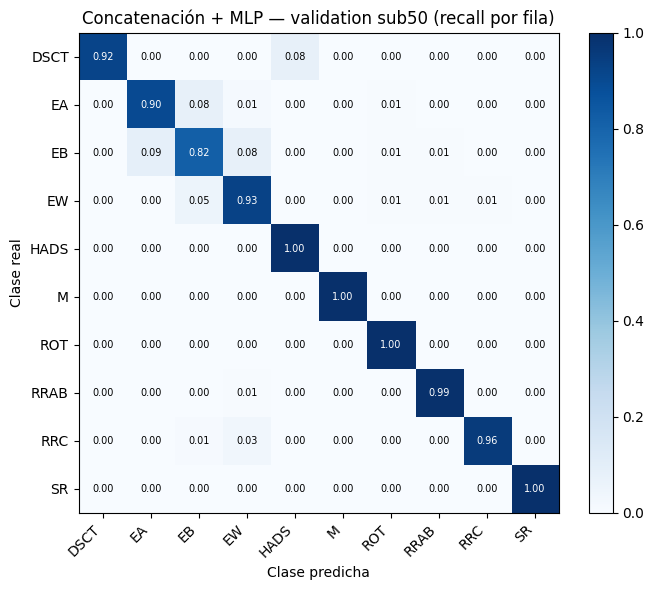


===== Concatenación + MLP | test =====
              precision    recall  f1-score   support

        DSCT       0.96      0.92      0.94        24
          EA       0.88      0.89      0.89       160
          EB       0.82      0.80      0.81       160
          EW       0.92      0.89      0.91       160
        HADS       0.89      0.96      0.93        26
           M       1.00      0.95      0.98        22
         ROT       0.96      1.00      0.98       160
        RRAB       0.98      0.99      0.98       160
         RRC       1.00      0.95      0.97        79
          SR       0.99      1.00      1.00       160

    accuracy                           0.93      1111
   macro avg       0.94      0.94      0.94      1111
weighted avg       0.93      0.93      0.93      1111



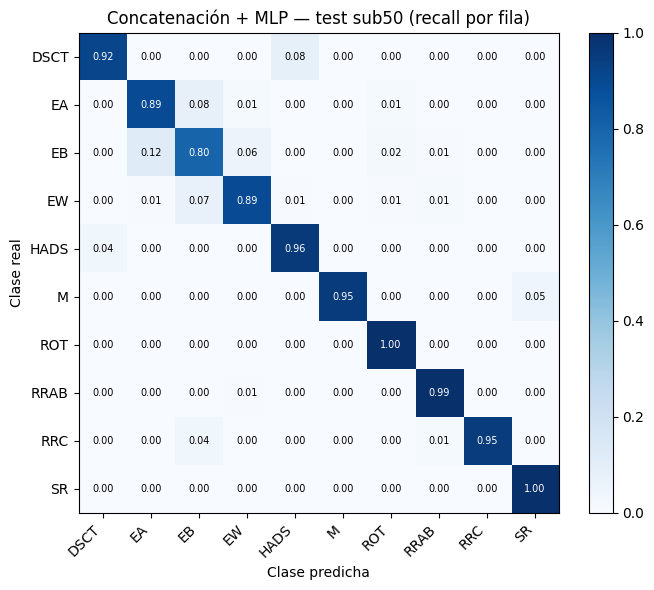


===== AstroM3-CLIP congelado + MLP | validation =====
              precision    recall  f1-score   support

        DSCT       0.96      0.96      0.96        25
          EA       0.87      0.91      0.89       149
          EB       0.84      0.77      0.80       149
          EW       0.88      0.93      0.91       149
        HADS       0.93      0.97      0.95        29
           M       0.97      0.97      0.97        30
         ROT       0.99      1.00      0.99       149
        RRAB       0.99      0.98      0.98       149
         RRC       0.98      0.94      0.96        93
          SR       0.99      0.99      0.99       149

    accuracy                           0.93      1071
   macro avg       0.94      0.94      0.94      1071
weighted avg       0.93      0.93      0.93      1071



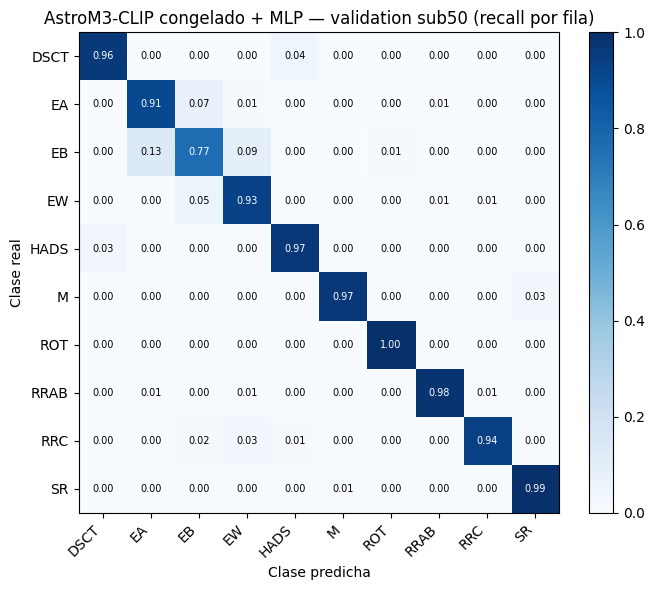


===== AstroM3-CLIP congelado + MLP | test =====
              precision    recall  f1-score   support

        DSCT       0.96      0.92      0.94        24
          EA       0.84      0.88      0.86       160
          EB       0.79      0.73      0.76       160
          EW       0.89      0.89      0.89       160
        HADS       0.92      0.92      0.92        26
           M       1.00      0.95      0.98        22
         ROT       0.96      0.99      0.98       160
        RRAB       0.99      1.00      0.99       160
         RRC       0.97      0.94      0.95        79
          SR       0.99      1.00      0.99       160

    accuracy                           0.92      1111
   macro avg       0.93      0.92      0.93      1111
weighted avg       0.92      0.92      0.92      1111



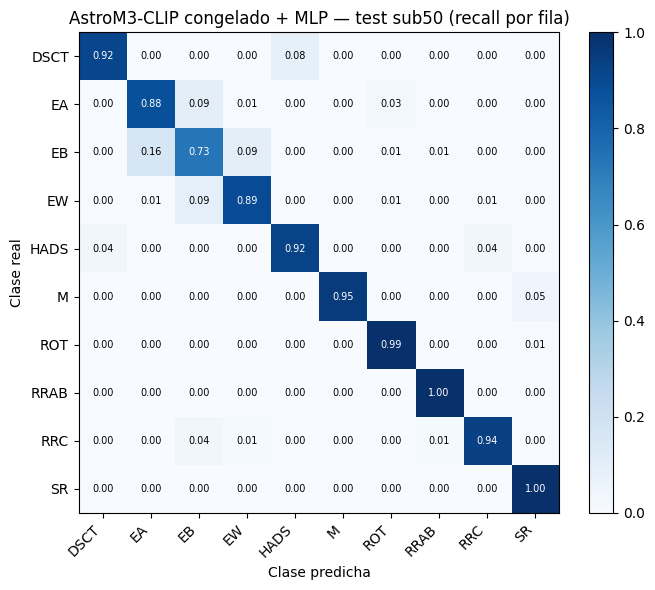


===== AstroM3-CLIP ajuste fino | validation =====
              precision    recall  f1-score   support

        DSCT       0.96      0.96      0.96        25
          EA       0.85      0.83      0.84       149
          EB       0.79      0.81      0.80       149
          EW       0.90      0.91      0.90       149
        HADS       0.96      0.86      0.91        29
           M       0.94      1.00      0.97        30
         ROT       0.95      1.00      0.97       149
        RRAB       0.99      0.99      0.99       149
         RRC       0.98      0.92      0.95        93
          SR       1.00      0.99      0.99       149

    accuracy                           0.92      1071
   macro avg       0.93      0.93      0.93      1071
weighted avg       0.92      0.92      0.92      1071



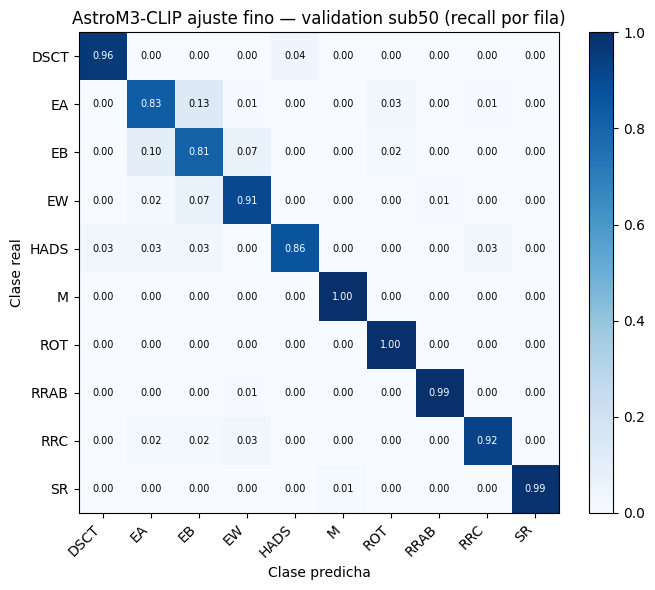


===== AstroM3-CLIP ajuste fino | test =====
              precision    recall  f1-score   support

        DSCT       0.88      0.92      0.90        24
          EA       0.87      0.88      0.87       160
          EB       0.80      0.78      0.79       160
          EW       0.89      0.89      0.89       160
        HADS       0.96      0.85      0.90        26
           M       1.00      1.00      1.00        22
         ROT       0.95      1.00      0.97       160
        RRAB       1.00      1.00      1.00       160
         RRC       0.99      0.94      0.96        79
          SR       0.99      1.00      1.00       160

    accuracy                           0.92      1111
   macro avg       0.93      0.92      0.93      1111
weighted avg       0.92      0.92      0.92      1111



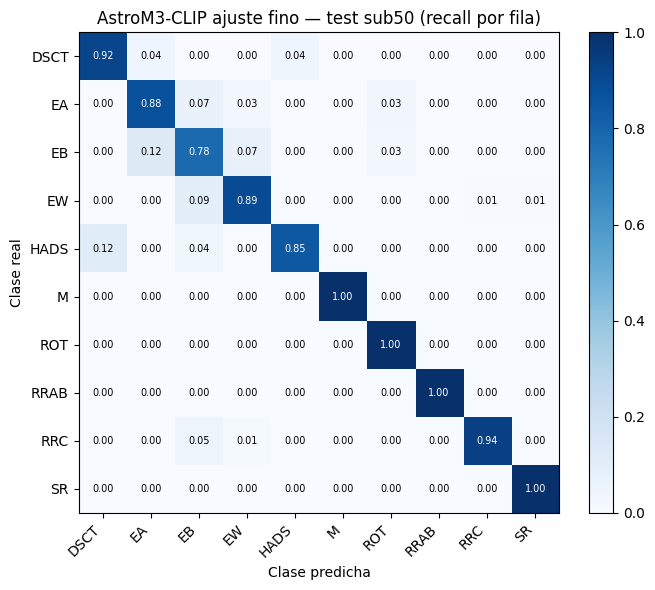

In [22]:
for name in ("Concatenación + MLP", "AstroM3-CLIP congelado + MLP", "AstroM3-CLIP ajuste fino"):
    for split in Y:
        print(f"\n===== {name} | {split} =====")
        print(SUMMARY[split][name]["report_text"])
        reporting.plot_confusion_matrix(SUMMARY[split][name]["confusion_matrix"], title=f"{name} — {split} {SUBSET} (recall por fila)")
        plt.show()

## 8. Resumen guardado

In [23]:
def clean(m):
    return {"accuracy": float(m["accuracy"]), "macro_f1": float(m["macro_f1"]),
            "per_class_f1": {c: float(v["f1"]) for c, v in m["per_class"].items()}}

results = {
    "subset": SUBSET, "seed": config.SEED, "device": DEVICE, "gpu": GPU, "torch": torch.__version__,
    "astrom3_commit": transfer.ASTROM3_COMMIT, "clip_model": config.CLIP_MODEL_NAME,
    "audit": AUDIT.reset_index().to_dict(orient="records") if AUDIT is not None else None,
    "audit_verdict": VERDICT,
    "unimodal_cost": COST,
    "vote": {"chosen_tie_break": CHOSEN_RULE, "val_macro_f1_by_rule": VAL_RULE},
    "concat": {"grid": GS_CONCAT["table"], "chosen": CONCAT["params"], "best_epoch": CONCAT["best_epoch"],
               "ablation": ABLATION.to_dict(orient="index")},
    "astrom3_frozen": {"grid": GS_FROZEN["table"], "chosen": FROZEN["params"], "best_epoch": FROZEN["best_epoch"],
                       "extract_seconds": CLIP_EXTRACT_SECONDS},
    "astrom3_finetune": {"hp": HP, "best_epoch": FT["best_epoch"], "stopped_epoch": FT["stopped_epoch"],
                         "history": FT["history"]},
    "comparison": TABLE.to_dict(orient="index"),
    "bootstrap_vs_photometry": BOOT_PHOT.to_dict(orient="index"),
    "bootstrap_vs_concat": BOOT_CONCAT.to_dict(orient="index"),
    "per_split": {split: {name: clean(m) for name, m in SUMMARY[split].items()} for split in Y},
}
with open(OUT / "results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Guardado:", OUT / "results.json")

Guardado: outputs_e3/results.json
